# Notebook 06: Problem 2 — Severe Pollution Episode Forecasting
**Project:** Exploratory Data Analysis of Air Pollution in Indian Cities
**Course:** IT 462 — Exploratory Data Analysis | Autumn Semester
**Mentor:** Dr. Gopinath Panda

**Research Question:** Can we predict whether the next day will experience severe pollution using information available up to the current day?

This notebook implements:
1. Target definition: next-day PM2.5 in the top 12% of all city-days (>= 78.39 µg/m³, see `outputs/tables/severe_threshold.json`).
2. Strict chronological Train / Val / Test splitting.
3. Persistence baseline benchmarking (tomorrow equals today).
4. Supervised classification comparison (Logistic Regression, Random Forest, HistGradientBoosting, SVC).
5. Spatial cross-city generalization test on unseen cities.

In [1]:
import os, sys
import pandas as pd
from IPython.display import Image, display
from pathlib import Path

PROJECT_ROOT = Path(".").resolve().parents[0] if Path(".").resolve().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import TABLES_DIR, FIGURES_DIR

## 1. Out-of-Sample Model Comparison Table

In [2]:
df_cls = pd.read_csv(TABLES_DIR / "problem2_classification_comparison.csv")
df_cls

,Model,Type,Threshold,Severe_Precision,Severe_Recall,Severe_F1,ROC_AUC,PR_AUC,Test_Prevalence,Outperforms_Persistence
0,Persistence Baseline (Today=Tomorrow),Naive Benchmark,n/a (hard rule),0.782,0.791,0.786,0.845,0.684,0.315,Baseline
1,Logistic Regression (Balanced),Supervised Learning,0.622,0.737,0.857,0.792,0.937,0.879,0.315,Yes
2,Random Forest Classifier,Supervised Learning,0.503,0.673,0.934,0.782,0.932,0.857,0.315,No
3,HistGradientBoosting,Supervised Learning,0.226,0.718,0.837,0.773,0.927,0.863,0.315,No
4,Support Vector Classifier (RBF),Supervised Learning,0.1,0.624,0.965,0.758,0.880,0.681,0.315,No


## 2. Receiver Operating Characteristic & Precision-Recall Curves (Fig 14)

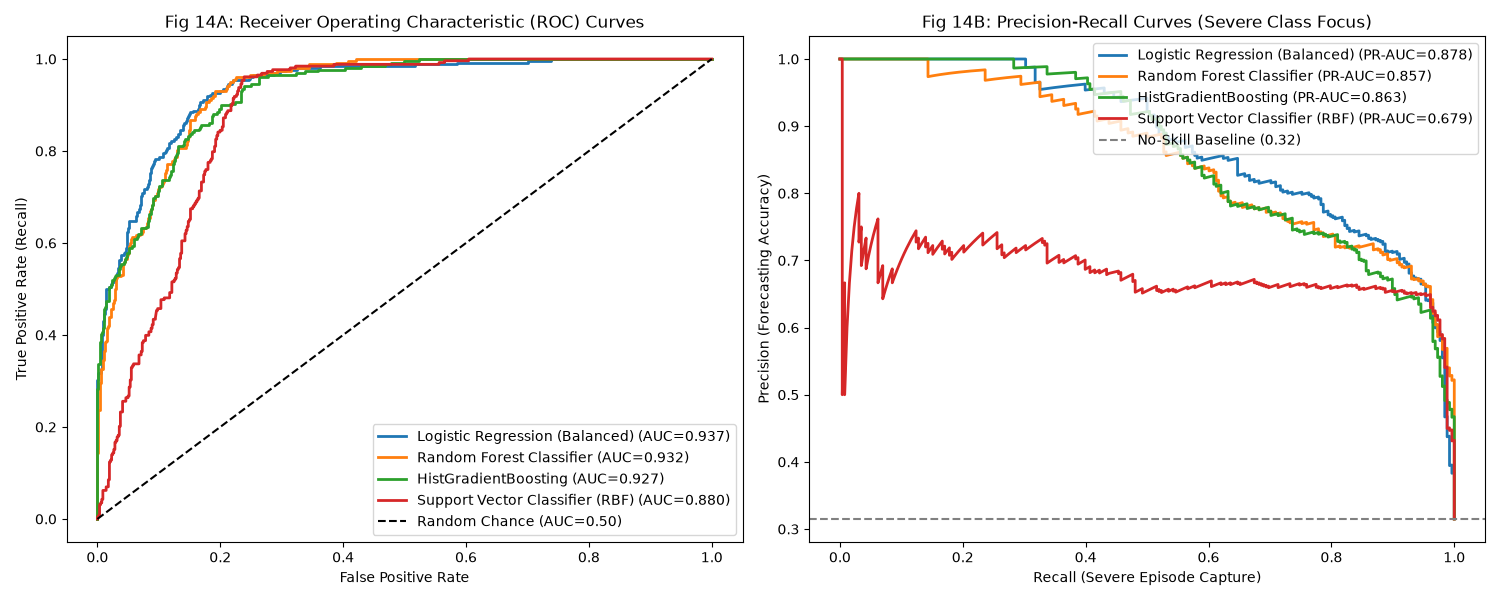

In [3]:
display(Image(filename=str(FIGURES_DIR / "fig14_pr_roc_curves.png")))

## 3. Confusion Matrix: Persistence vs. Best ML Model (Fig 15)

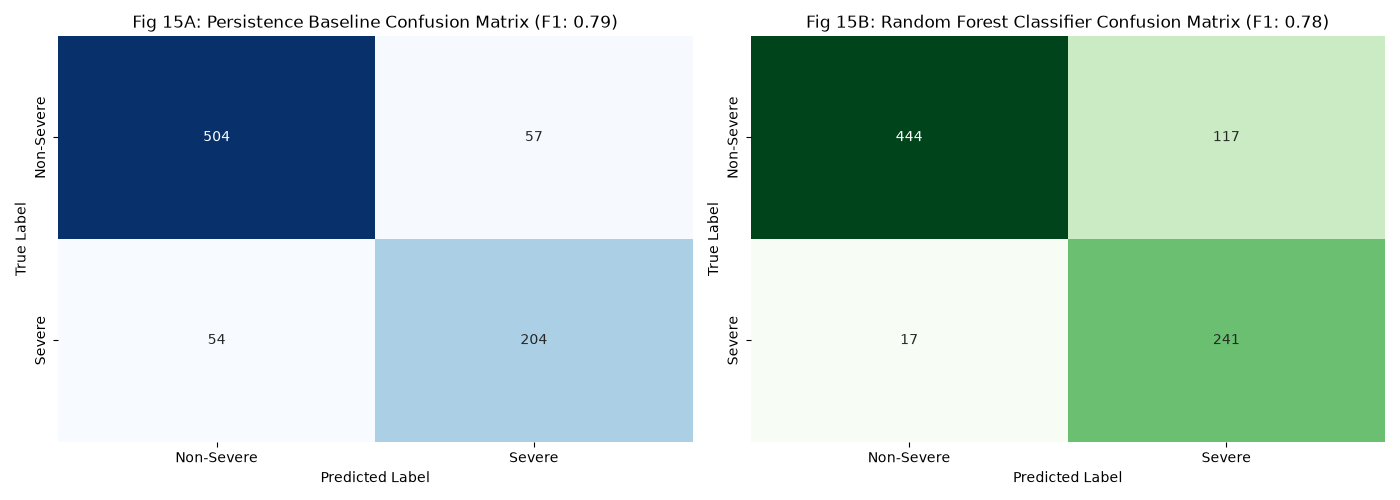

In [4]:
display(Image(filename=str(FIGURES_DIR / "fig15_confusion_matrices.png")))

## 4. Feature Importance Attribution (Fig 16)

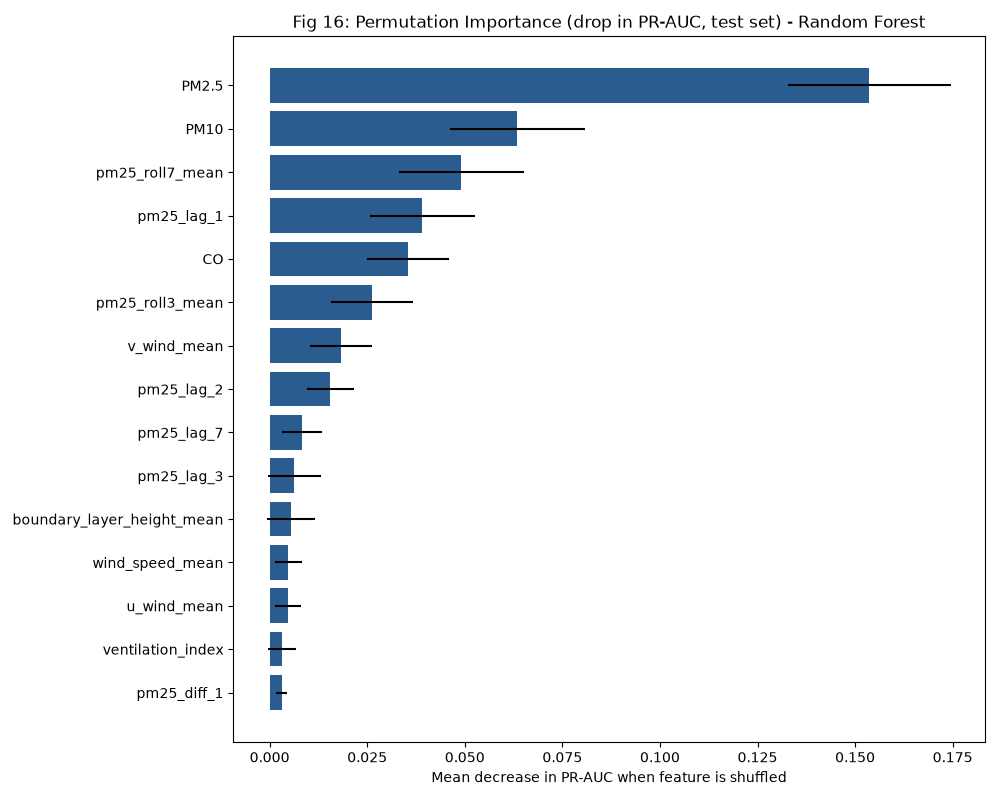

In [5]:
display(Image(filename=str(FIGURES_DIR / "fig16_shap_feature_importance.png")))